## 1. Chargement et suppression des doublons
Les doublons sont supprimés **avant** le découpage, sinon une même ligne peut se retrouver dans l'entraînement et dans le test.

In [2]:
import sys, json
sys.path.append("..")            # pour importer ml-research/src

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, matthews_corrcoef
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from src.data_prep import SEED, V_COLS, load_clean, make_splits, build_preprocessor, input_columns

sns.set_theme(style="whitegrid")
df = load_clean("../datasets/creditcard.csv")
print(df.shape)
print(df["Class"].value_counts())

assert df.shape == (283726, 31), "Nombre de lignes inattendu"
assert df["Class"].sum() == 473, "Nombre de fraudes inattendu"

(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


## 2. Découpage stratifié : entraînement / calibration / test
- **Entraînement (60 %)** : le modèle apprend dessus.
- **Calibration (20 %)** : réservé à l'incertitude (conformal, T4).
- **Test (20 %)** : **on n'y touche pas** avant l'évaluation finale.

« Stratifié » = même proportion de fraudes dans chaque lot.

In [3]:
splits = make_splits(df)

rows = []
for name, (X, y) in splits.items():
    rows.append({"lot": name, "lignes": len(y), "fraudes": int(y.sum()), "taux_fraude_%": round(100 * y.mean(), 4)})
summary = pd.DataFrame(rows).set_index("lot")
summary

,lignes,fraudes,taux_fraude_%
lot,,,
train,170235,284,0.1668
cal,56745,94,0.1657
test,56746,95,0.1674


In [4]:
# Vérifications : tout est cohérent ?
assert summary["lignes"].sum() == len(df)
assert summary["fraudes"].sum() == 473
rates = summary["taux_fraude_%"]
assert rates.max() - rates.min() < 0.05, "Stratification suspecte"

# Aucun chevauchement entre les lots
idx = {k: set(v[0].index) for k, v in splits.items()}
assert not (idx["train"] & idx["cal"]) and not (idx["train"] & idx["test"]) and not (idx["cal"] & idx["test"])
print("OK : lots disjoints et stratifiés")

OK : lots disjoints et stratifiés


## 3. Transformation de `Amount` (sur l'entraînement uniquement)
L'asymétrie (skewness) mesure à quel point la distribution est étirée : proche de 0 = symétrique.

Skewness Amount brut     : 15.2
Skewness log(1 + Amount) : 0.16


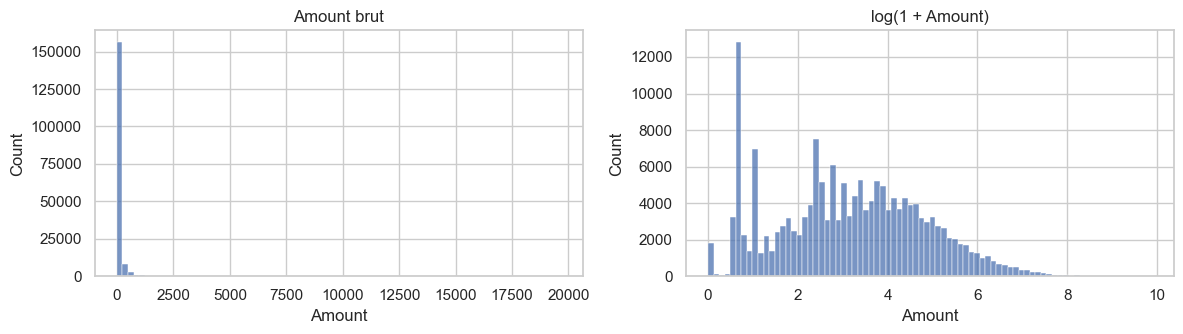

In [5]:
X_train, y_train = splits["train"]
a = X_train["Amount"]
print("Skewness Amount brut     :", round(skew(a), 2))
print("Skewness log(1 + Amount) :", round(skew(np.log1p(a)), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(a, bins=80, ax=ax[0]); ax[0].set_title("Amount brut")
sns.histplot(np.log1p(a), bins=80, ax=ax[1]); ax[1].set_title("log(1 + Amount)")
plt.tight_layout(); plt.show()

## 4. Faut-il garder `Time` ? (test avec / sans)
On compare la **PR-AUC** en validation croisée 5 plis, sur l'entraînement seulement.  
Règle : on garde `Time` uniquement si le gain dépasse l'écart-type (sinon c'est du bruit). Cette cellule prend quelques minutes.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_score(include_time):
    pipe = ImbPipeline([
        ("prep", build_preprocessor(include_time=include_time)),
        ("clf", HistGradientBoostingClassifier(random_state=SEED)),
    ])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    return res["test_score"]

without_time = cv_score(False)
with_time = cv_score(True)
print(f"Sans Time : PR-AUC = {without_time.mean():.4f} +/- {without_time.std():.4f}")
print(f"Avec Time : PR-AUC = {with_time.mean():.4f} +/- {with_time.std():.4f}")
print("Gain :", round(with_time.mean() - without_time.mean(), 4))

Sans Time : PR-AUC = 0.6057 +/- 0.0986
Avec Time : PR-AUC = 0.6136 +/- 0.0491
Gain : 0.0079


## 5. Gérer le déséquilibre : rien vs `class_weight` vs SMOTE
- **class_weight** : on dit au modèle qu'une fraude manquée coûte beaucoup plus cher.
- **SMOTE** : on fabrique des fraudes synthétiques **dans l'entraînement seulement**, grâce à un Pipeline imblearn qui l'applique pli par pli (donc sans fuite).

Critère principal : **PR-AUC**. Le MCC est calculé au seuil 0,5 : il dépend du seuil, donc à lire avec prudence.

In [7]:
scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "mcc": make_scorer(matthews_corrcoef),
}
prep = lambda: build_preprocessor(include_time=False)

variants = {
    "Aucun traitement": ImbPipeline([("prep", prep()), ("clf", LogisticRegression(max_iter=1000))]),
    "class_weight": ImbPipeline([("prep", prep()), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "SMOTE (10 %)": ImbPipeline([("prep", prep()), ("smote", SMOTE(sampling_strategy=0.1, random_state=SEED)),
                                 ("clf", LogisticRegression(max_iter=1000))]),
}

rows = []
for name, pipe in variants.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "stratégie": name,
        "PR-AUC": f"{res['test_pr_auc'].mean():.4f} +/- {res['test_pr_auc'].std():.4f}",
        "ROC-AUC": f"{res['test_roc_auc'].mean():.4f}",
        "MCC": f"{res['test_mcc'].mean():.4f}",
    })
pd.DataFrame(rows).set_index("stratégie")

,PR-AUC,ROC-AUC,MCC
stratégie,,,
Aucun traitement,0.7352 +/- 0.0583,0.9788,0.7096
class_weight,0.7352 +/- 0.0527,0.9813,0.2119
SMOTE (10 %),0.7388 +/- 0.0613,0.9783,0.5773


### Décision (à écrire avec TES chiffres)
### Décision
- **Time : retiré.** PR-AUC sans Time = 0,6057 ± 0,0986, avec Time = 0,6136 ± 0,0491 : gain (+0,008) très inférieur à l'écart-type, donc pas d'apport démontré. Time mesure des secondes sur 48 h seulement (risque de mauvaise généralisation) et n'a pas d'équivalent à l'inférence, ce qui simplifie le contrat d'API.
- **Déséquilibre : aucun traitement dans le pipeline.** PR-AUC (régression logistique, validation croisée 5 plis) : aucun traitement 0,7352 ± 0,0583 ; class_weight 0,7352 ± 0,0527 ; SMOTE 0,7388 ± 0,0613. Différences négligeables devant les écarts-types. Le MCC à seuil 0,5 est meilleur sans traitement (0,71 contre 0,21 et 0,58), car class_weight et SMOTE gonflent les probabilités, ce qui fausserait les seuils de la règle de décision (0,5 / 0,9) et la calibration de la tâche 4.
- **Limites** : test réalisé sur la régression logistique seulement ; le poids des classes sera retesté comme hyperparamètre pour les autres modèles en P2.4. Environ 57 fraudes par pli de validation, d'où des écarts-types élevés.



## 6. Le Pipeline final : vérifier qu'il n'y a pas de fuite

In [8]:
# >>> À MODIFIER selon tes résultats <<<
INCLUDE_TIME = False
IMBALANCE_STRATEGY = "none"     # "class_weight" ou "smote" ou "none"

prep_final = build_preprocessor(include_time=INCLUDE_TIME)
Z_train = prep_final.fit_transform(X_train)          # apprend les moyennes/écarts-types sur le train
Z_cal = prep_final.transform(splits["cal"][0])       # applique, sans réapprendre
Z_test = prep_final.transform(splits["test"][0])

print("Forme train / cal / test :", Z_train.shape, Z_cal.shape, Z_test.shape)
print("Train : moyenne max |m| =", np.abs(Z_train.mean(axis=0)).max().round(4),
      "| écart-type moyen =", Z_train.std(axis=0).mean().round(3))
print("Cal   : moyenne max |m| =", np.abs(Z_cal.mean(axis=0)).max().round(4), "(proche de 0 mais pas exactement : normal)")

Forme train / cal / test : (170235, 29) (56745, 29) (56746, 29)
Train : moyenne max |m| = 0.0 | écart-type moyen = 1.0
Cal   : moyenne max |m| = 0.0123 (proche de 0 mais pas exactement : normal)


## 7. Schéma de features (contrat avec P3)
Ce fichier dit à P3 **exactement** quelles colonnes brutes envoyer au pipeline et comment elles sont transformées.

In [9]:
from pathlib import Path

schema = {
    "schema_version": "1.0.0",
    "dataset": "creditcard (ULB/Kaggle), doublons supprimés",
    "seed": SEED,
    "target": "Class",
    "input_columns": input_columns(INCLUDE_TIME),
    "transformations": {
        "Amount": "log1p puis StandardScaler",
        "V1..V28": "StandardScaler",
        "Time": "StandardScaler" if INCLUDE_TIME else "non utilisée",
    },
    "imbalance_strategy": IMBALANCE_STRATEGY,
    "splits": {
        name: {"rows": int(len(y)), "frauds": int(y.sum())} for name, (X, y) in splits.items()
    },
    "notes": "Le pipeline reçoit les colonnes BRUTES (DataFrame avec ces noms) et applique les transformations lui-même.",
}

out = Path("../artifacts"); out.mkdir(exist_ok=True)
(out / "feature_schema.json").write_text(json.dumps(schema, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(schema, indent=2, ensure_ascii=False))

{
  "schema_version": "1.0.0",
  "dataset": "creditcard (ULB/Kaggle), doublons supprimés",
  "seed": 42,
  "target": "Class",
  "input_columns": [
    "V1",
    "V2",
    "V3",
    "V4",
    "V5",
    "V6",
    "V7",
    "V8",
    "V9",
    "V10",
    "V11",
    "V12",
    "V13",
    "V14",
    "V15",
    "V16",
    "V17",
    "V18",
    "V19",
    "V20",
    "V21",
    "V22",
    "V23",
    "V24",
    "V25",
    "V26",
    "V27",
    "V28",
    "Amount"
  ],
  "transformations": {
    "Amount": "log1p puis StandardScaler",
    "V1..V28": "StandardScaler",
    "Time": "non utilisée"
  },
  "imbalance_strategy": "none",
  "splits": {
    "train": {
      "rows": 170235,
      "frauds": 284
    },
    "cal": {
      "rows": 56745,
      "frauds": 94
    },
    "test": {
      "rows": 56746,
      "frauds": 95
    }
  },
  "notes": "Le pipeline reçoit les colonnes BRUTES (DataFrame avec ces noms) et applique les transformations lui-même."
}


## 8. Conclusions de P2.2
- **Doublons** : 1 081 supprimés (1 062 légitimes, 19 fraudes) avant le découpage → 283 726 lignes, dont 473 fraudes.
- **Découpage** : 60/20/20 stratifié, graine 42. Fraudes : train 284, calibration 94, test 95 (taux de 0,166 à 0,167 % partout). Lots disjoints vérifiés.
- **Amount** : skewness de 15,2 à 0,16 avec log(1 + x), puis standardisation apprise sur le train.
- **Time** : retiré (gain de PR-AUC de +0,008, très inférieur à l'écart-type).
- **Déséquilibre** : aucun traitement dans le pipeline (PR-AUC équivalente, probabilités mieux calibrées) ; poids des classes retesté par modèle en P2.4.
- **Feature engineering** : aucune variable créée, car V1…V28 sont anonymisées (PCA).
- **Sans fuite** : transformations apprises sur le train seulement ; lot de test non utilisé pour décider.
- **Limites** : 94 fraudes en calibration et 95 en test → résultats variables, d'où la validation croisée répétée (T3).
- **Livrables** : `src/data_prep.py`, `artifacts/feature_schema.json`, `artifacts/feature_input.schema.json` (JSON Schema, validé par `src/make_schema.py`) et `artifacts/feature_input.example.json`.